# Mask R-CNN


## 1. Environment and imports

In [1]:
%pip install -q pycocotools tqdm "supervision[metrics]==0.31.3"


Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import json
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import torch

## 2. Dataset configuration and checks

In [3]:
root = Path("/kaggle/input/datasets/paibarrr/panoptic-indoor-segmentation-coco/")
train = root / "train"
valid = root / "valid"
test = root / "test"
dst = Path("/kaggle/working/mask_rcnn_runs")
DATASET_DIR = root
OUTPUT_DIR = dst
CHECKPOINT_DIR = dst
RUN_TRAINING = True
RESUME_PRETRAINED = None
RESUME_SCRATCH = None
MASKRCNN_SCRIPT = Path("/kaggle/working/train_maskrcnn.py")
EPOCHS = 50
GPU_COUNT = 2

assert torch.cuda.is_available(), "Enable a Kaggle GPU accelerator."
assert torch.cuda.device_count() >= GPU_COUNT, "Select the Kaggle dual T4 GPU accelerator."

print(f"Dataset: {DATASET_DIR}")
print(f"GPUs: {torch.cuda.device_count()}")
for gpu_index in range(torch.cuda.device_count()):
    print(f"GPU {gpu_index}: {torch.cuda.get_device_name(gpu_index)}")

Dataset: /kaggle/input/datasets/paibarrr/panoptic-indoor-segmentation-coco
GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [4]:
for split, split_dir in (("train", train), ("valid", valid), ("test", test)):
    annotation_file = split_dir / "_annotations.coco.json"
    annotations = json.loads(annotation_file.read_text())
    print(f"{split}: {len(annotations['images'])} images, {len(annotations['annotations'])} annotations")

train_annotations = json.loads((train / "_annotations.coco.json").read_text())
print(f"Classes: {len(train_annotations['categories'])}")

train: 397 images, 4479 annotations
valid: 166 images, 2022 annotations
test: 359 images, 5344 annotations
Classes: 75


## 3. Output directories and artifacts

In [5]:
ARTIFACT_DIR = OUTPUT_DIR / "report_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

class_distribution = []
dataset_summary = {"dataset_dir": str(DATASET_DIR), "splits": {}, "classes": train_annotations["categories"]}

for split, split_dir in (("train", train), ("valid", valid), ("test", test)):
    annotation_data = json.loads((split_dir / "_annotations.coco.json").read_text())
    category_names = {item["id"]: item["name"] for item in annotation_data["categories"]}
    instance_counts = {category_id: 0 for category_id in category_names}
    for annotation in annotation_data["annotations"]:
        instance_counts[annotation["category_id"]] += 1
    dataset_summary["splits"][split] = {
        "images": len(annotation_data["images"]),
        "annotations": len(annotation_data["annotations"]),
    }
    class_distribution.extend([
        {"split": split, "class_id": category_id, "class_name": category_names[category_id], "instances": count}
        for category_id, count in instance_counts.items()
    ])

(ARTIFACT_DIR / "dataset_summary.json").write_text(json.dumps(dataset_summary, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "class_names.json").write_text(
    json.dumps([item["name"] for item in train_annotations["categories"]], indent=2),
    encoding="utf-8",
)
with (ARTIFACT_DIR / "class_distribution.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["split", "class_id", "class_name", "instances"])
    writer.writeheader()
    writer.writerows(class_distribution)



## 4. Model and training setup

In [6]:
%%writefile /kaggle/working/train_maskrcnn.py
import argparse
import csv
import contextlib
import io
import random
import numpy as np
import os
import shutil
import time
from pathlib import Path

import torch
import torch.distributed as distributed
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils
from torch.nn.parallel import DistributedDataParallel
from torch.utils.data import DataLoader, Dataset
from torch.utils.data.distributed import DistributedSampler
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_Weights, maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.transforms.functional import to_tensor
from tqdm.auto import tqdm

class COCOSegmentationDataset(Dataset):
    def __init__(self, image_dir, annotation_file, class_names=None):
        self.image_dir = Path(image_dir)
        self.coco = COCO(str(annotation_file))
        self.image_ids = sorted(self.coco.getImgIds())
        categories = self.coco.loadCats(self.coco.getCatIds())
        if class_names is None:
            self.category_map = {
                category_id: index + 1
                for index, category_id in enumerate(sorted(self.coco.getCatIds()))
            }
        else:
            name_to_index = {name: index + 1 for index, name in enumerate(class_names)}
            unknown_names = [category["name"] for category in categories if category["name"] not in name_to_index]
            if unknown_names:
                raise ValueError(f"Unknown dataset classes: {unknown_names}")
            self.category_map = {
                category["id"]: name_to_index[category["name"]]
                for category in categories
            }

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image_info = self.coco.loadImgs(image_id)[0]
        image = Image.open(self.image_dir / image_info["file_name"]).convert("RGB")
        if image.size == (image_info["height"], image_info["width"]) and image.width != image.height:
            image = image.transpose(Image.Transpose.ROTATE_270)
        annotations = self.coco.loadAnns(self.coco.getAnnIds(imgIds=image_id))
        annotations = [item for item in annotations if not item.get("iscrowd", 0)]
        boxes, labels, masks = [], [], []
        for item in annotations:
            x, y, width, height = item["bbox"]
            mask = self.coco.annToMask(item)
            if width <= 0 or height <= 0 or not mask.any():
                continue
            boxes.append([x, y, x + width, y + height])
            labels.append(self.category_map[item["category_id"]])
            masks.append(mask)
        if masks:
            masks = torch.as_tensor(masks, dtype=torch.uint8)
        else:
            masks = torch.zeros((0, image.height, image.width), dtype=torch.uint8)
        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "masks": masks,
            "image_id": torch.tensor([image_id]),
        }
        return to_tensor(image), target

def build_model(num_classes, pretrained=False):
    weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT if pretrained else None
    model = maskrcnn_resnet50_fpn(
        weights=weights,
        weights_backbone=None,
        trainable_backbone_layers=5,
    )
    box_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(box_features, num_classes)
    mask_features = model.roi_heads.mask_predictor.conv5_mask.in_channels
    mask_hidden = model.roi_heads.mask_predictor.conv5_mask.out_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_features, mask_hidden, num_classes)
    return model


def collate_fn(batch):
    return tuple(zip(*batch))

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--dataset-dir", required=True)
    parser.add_argument("--output-dir", required=True)
    parser.add_argument("--num-classes", type=int, required=True)
    parser.add_argument("--weights", choices=("pretrained", "scratch"), required=True)
    parser.add_argument("--epochs", type=int, required=True)
    parser.add_argument("--resume", default="")
    args = parser.parse_args()

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    distributed.init_process_group(backend="nccl")
    local_rank = int(os.environ["LOCAL_RANK"])
    rank = distributed.get_rank()
    torch.cuda.set_device(local_rank)
    device = torch.device("cuda", local_rank)

    dataset_dir = Path(args.dataset_dir)
    dataset = COCOSegmentationDataset(
        dataset_dir / "train",
        dataset_dir / "train" / "_annotations.coco.json",
    )
    class_names = [
        category["name"]
        for category in sorted(dataset.coco.loadCats(dataset.coco.getCatIds()), key=lambda item: item["id"])
    ]
    valid_dataset = COCOSegmentationDataset(
        dataset_dir / "valid",
        dataset_dir / "valid" / "_annotations.coco.json",
        class_names,
    )
    sampler = DistributedSampler(dataset, shuffle=True, seed=42)
    loader = DataLoader(
        dataset,
        batch_size=2,
        sampler=sampler,
        num_workers=2,
        collate_fn=collate_fn,
        pin_memory=True,
    )

    model = build_model(args.num_classes, args.weights == "pretrained")
    model = DistributedDataParallel(model.to(device), device_ids=[local_rank])
    optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)

    start_epoch = 0
    best_map = -1.0
    if args.resume:
        checkpoint = torch.load(args.resume, map_location="cpu", weights_only=False)
        model.module.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        start_epoch = checkpoint["epoch"]
        best_map = checkpoint.get("best_map", -1.0)

    output_dir = Path(args.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    training_log = output_dir / "training_log.csv"
    if args.resume and not training_log.exists():
        previous_log = Path(args.resume).parent / "training_log.csv"
        if previous_log.exists():
            shutil.copy2(previous_log, training_log)
    if not training_log.exists():
        with training_log.open("w", newline="", encoding="utf-8") as file:
            csv.writer(file).writerow(["epoch", "train_loss", "val_mask_map50_95", "epoch_seconds"])

    for epoch in range(start_epoch, args.epochs):
        epoch_start = time.perf_counter()
        sampler.set_epoch(epoch)
        model.train()
        total_loss = 0.0
        progress = tqdm(
            loader,
            desc=f"Epoch {epoch + 1}/{args.epochs}",
            disable=rank != 0,
            mininterval=30,
        )
        for images, targets in progress:
            images = [image.to(device, non_blocking=True) for image in images]
            targets = [
                {key: value.to(device, non_blocking=True) for key, value in target.items()}
                for target in targets
            ]
            loss = sum(model(images, targets).values())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.detach().item()
            progress.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = torch.tensor(total_loss / len(loader), device=device)
        distributed.all_reduce(epoch_loss, op=distributed.ReduceOp.SUM)
        epoch_loss = (epoch_loss / distributed.get_world_size()).item()
        epoch_seconds = time.perf_counter() - epoch_start

        if rank == 0:
            model.module.eval()
            model.module.roi_heads.score_thresh = 0.001
            predictions = []
            category_ids = sorted(dataset.coco.getCatIds())
            with torch.inference_mode():
                for image_index in range(len(valid_dataset)):
                    image, target = valid_dataset[image_index]
                    output = model.module([image.to(device)])[0]
                    for box_mask, label, score in zip(output["masks"], output["labels"], output["scores"]):
                        mask = (box_mask[0].cpu().numpy() > 0.5).astype(np.uint8)
                        encoded = mask_utils.encode(np.asfortranarray(mask))
                        encoded["counts"] = encoded["counts"].decode("ascii")
                        predictions.append({
                            "image_id": int(target["image_id"].item()),
                            "category_id": category_ids[int(label) - 1],
                            "segmentation": encoded,
                            "score": float(score),
                        })
            val_map = 0.0
            if predictions:
                with contextlib.redirect_stdout(io.StringIO()):
                    detections = valid_dataset.coco.loadRes(predictions)
                    evaluator = COCOeval(valid_dataset.coco, detections, "segm")
                    evaluator.evaluate()
                    evaluator.accumulate()
                    evaluator.summarize()
                val_map = float(evaluator.stats[0])
            improved = val_map > best_map
            best_map = max(best_map, val_map)
            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.module.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "weights": args.weights,
                "num_classes": args.num_classes,
                "class_names": class_names,
                "train_loss": epoch_loss,
                "val_mask_map50_95": val_map,
                "best_map": best_map,
                "epoch_seconds": epoch_seconds,
            }
            temporary_file = output_dir / "last.ckpt.tmp"
            torch.save(checkpoint, temporary_file)
            os.replace(temporary_file, output_dir / "last.ckpt")
            if improved:
                shutil.copy2(output_dir / "last.ckpt", output_dir / "best.ckpt")
            with training_log.open("a", newline="", encoding="utf-8") as file:
                csv.writer(file).writerow([epoch + 1, epoch_loss, val_map, round(epoch_seconds, 2)])
            print(
                f"Epoch {epoch + 1}/{args.epochs}, loss={epoch_loss:.4f}, val mask mAP={val_map:.4f}, "
                f"time={epoch_seconds / 60:.1f} min",
                flush=True,
            )
        distributed.barrier()

    distributed.destroy_process_group()

if __name__ == "__main__":
    main()


Writing /kaggle/working/train_maskrcnn.py


In [7]:
def run_maskrcnn(weights, resume_checkpoint=None):
    output_dir = OUTPUT_DIR / "maskrcnn" / weights
    output_dir.mkdir(parents=True, exist_ok=True)
    command = [
        sys.executable, "-m", "torch.distributed.run", "--standalone", "--nnodes=1",
        f"--nproc_per_node={GPU_COUNT}", str(MASKRCNN_SCRIPT),
        "--dataset-dir", str(DATASET_DIR), "--output-dir", str(output_dir),
        "--num-classes", str(len(train_annotations["categories"]) + 1),
        "--weights", weights, "--epochs", str(EPOCHS),
        "--resume", str(resume_checkpoint or ""),
    ]
    started_at = datetime.now(timezone.utc).isoformat()
    start_time = time.perf_counter()
    status = "failed"
    try:
        subprocess.run(command, check=True)
        status = "completed"
    finally:
        metadata = {
            "model": "Mask R-CNN ResNet50 FPN",
            "weights": weights,
            "status": status,
            "started_at_utc": started_at,
            "elapsed_wall_seconds": round(time.perf_counter() - start_time, 2),
            "dataset_dir": str(DATASET_DIR),
            "train_images": len(train_annotations["images"]),
            "classes": len(train_annotations["categories"]),
            "epochs": EPOCHS,
            "batch_size_per_gpu": 2,
            "optimizer": "SGD",
            "learning_rate": 0.005,
            "seed": 42,
            "strategy": "DDP",
            "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
            "training_log": str(output_dir / "training_log.csv"),
            "resume_checkpoint": str(output_dir / "last.ckpt"),
            "resumed_from": str(resume_checkpoint or ""),
            "inference_checkpoint": str(output_dir / "best.ckpt"),
        }
        (output_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
        (ARTIFACT_DIR / f"maskrcnn_{weights}_run_metadata.json").write_text(
            json.dumps(metadata, indent=2), encoding="utf-8"
        )


## 5. Training runs

In [8]:
if RUN_TRAINING:
    run_maskrcnn("pretrained", RESUME_PRETRAINED)



*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


loading annotations into memory...loading annotations into memory...

Done (t=0.05s)
creating index...
Done (t=0.05s)
creating index...
index created!
index created!
loading annotations into memory...
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Done (t=0.02s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 227MB/s]
100%|██████████| 170M/170M [00:01<00:00, 164MB/s]
Epoch 1/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider convert

Epoch 1/50, loss=2.4693, val mask mAP=0.0178, time=2.7 min


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
Epoch 2/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.ui

Epoch 2/50, loss=1.9374, val mask mAP=0.0354, time=2.7 min


... (92 outputs left out)

Epoch 49/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered

Epoch 49/50, loss=0.3015, val mask mAP=0.1643, time=2.8 min


Epoch 50/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered

Epoch 50/50, loss=0.3002, val mask mAP=0.1615, time=2.8 min


In [9]:
if RUN_TRAINING:
    run_maskrcnn("scratch", RESUME_SCRATCH)



*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


loading annotations into memory...loading annotations into memory...

Done (t=0.04s)
creating index...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Done (t=0.02s)
creating index...
index created!


/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(
Epoch 1/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = tor

Epoch 1/50, loss=2.5238, val mask mAP=0.0000, time=2.8 min


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
Epoch 2/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.ui

Epoch 2/50, loss=2.3231, val mask mAP=0.0001, time=2.8 min


... (92 outputs left out)

Epoch 49/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered

Epoch 49/50, loss=1.2578, val mask mAP=0.0329, time=3.1 min


Epoch 50/50:   0%|          | 0/100 [00:00<?, ?it/s]/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered

Epoch 50/50, loss=1.2400, val mask mAP=0.0291, time=3.0 min


## 6. Inference, metrics, and confusion matrix

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(masks, dtype=torch.uint8)
/kaggle/working/train_maskrcnn.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  masks = torch.as_tensor(m

Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.90s).
Accumulating evaluation results...
DONE (t=0.67s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.166
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.241
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.180
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.039
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.107
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.190
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.153
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.272
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.277
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


Loading and preparing results...
DONE (t=0.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=5.19s).
Accumulating evaluation results...
DONE (t=1.37s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.079
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.135
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.084
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.044
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.078
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.104
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.127
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.219
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.223
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=2.18s).
Accumulating evaluation results...
DONE (t=0.59s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.033
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.063
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.033
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.014
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.037
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.035
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.073
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.074
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

/usr/local/lib/python3.13/dist-packages/torchvision/models/detection/backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable
  warnings.warn(


Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.19s).
Accumulating evaluation results...
DONE (t=1.20s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.006
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.013
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.006
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.003
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.014
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.005
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.019
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.036
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.037
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

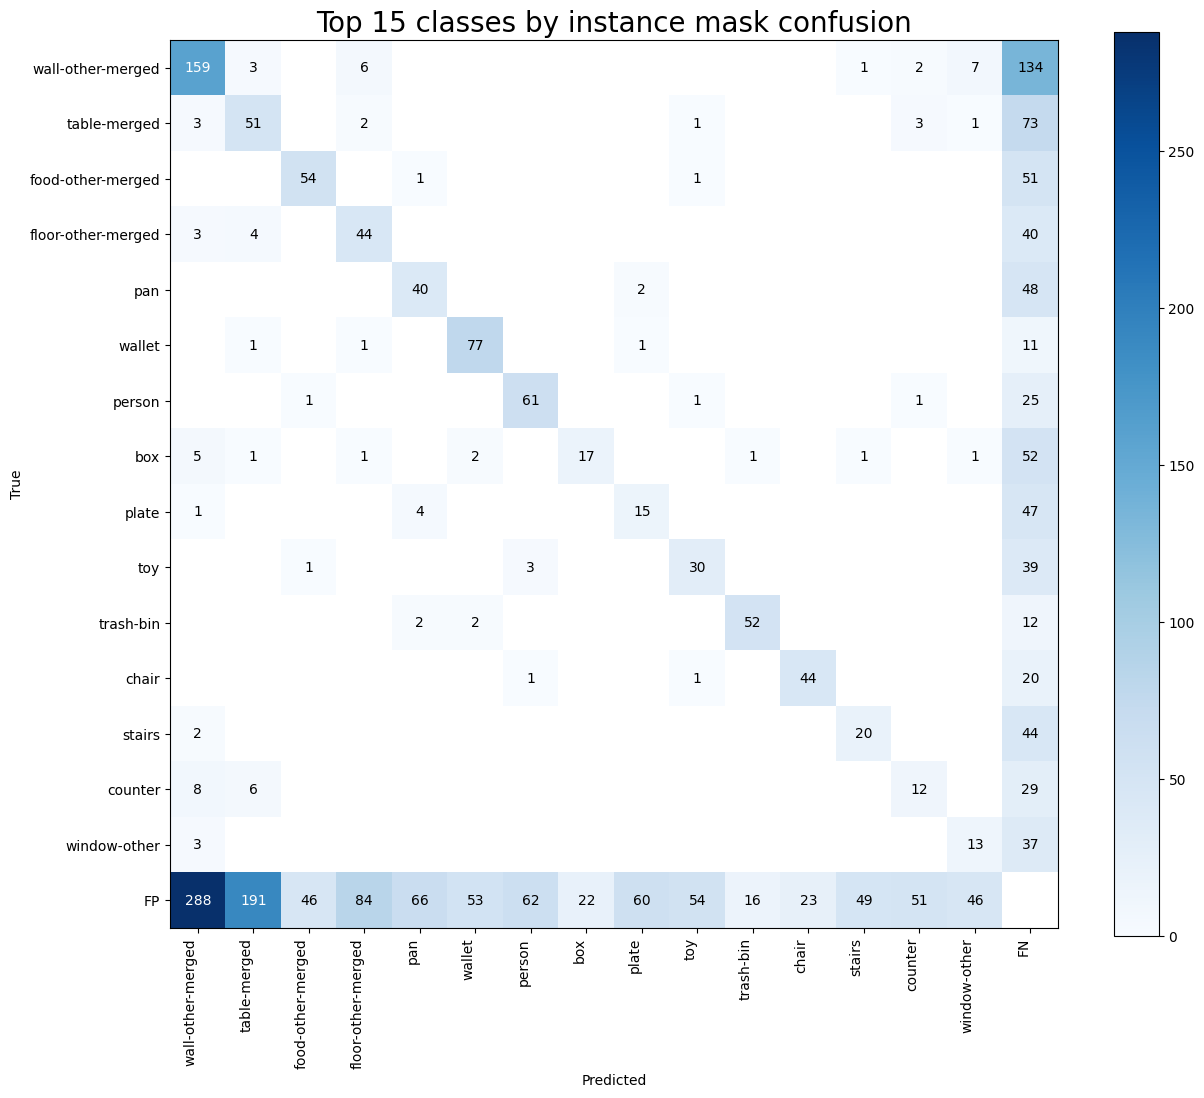

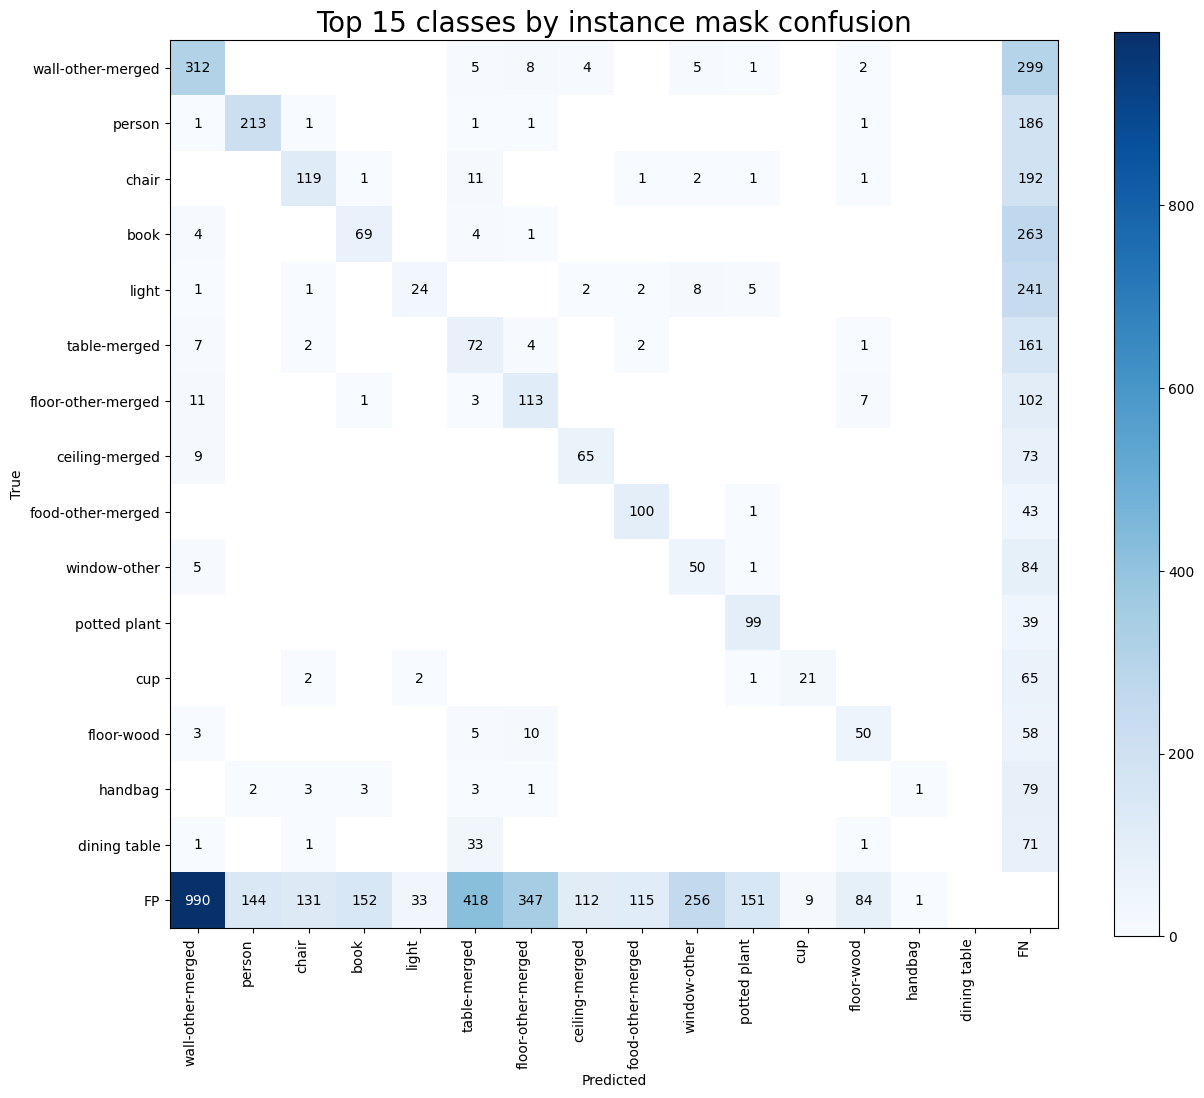

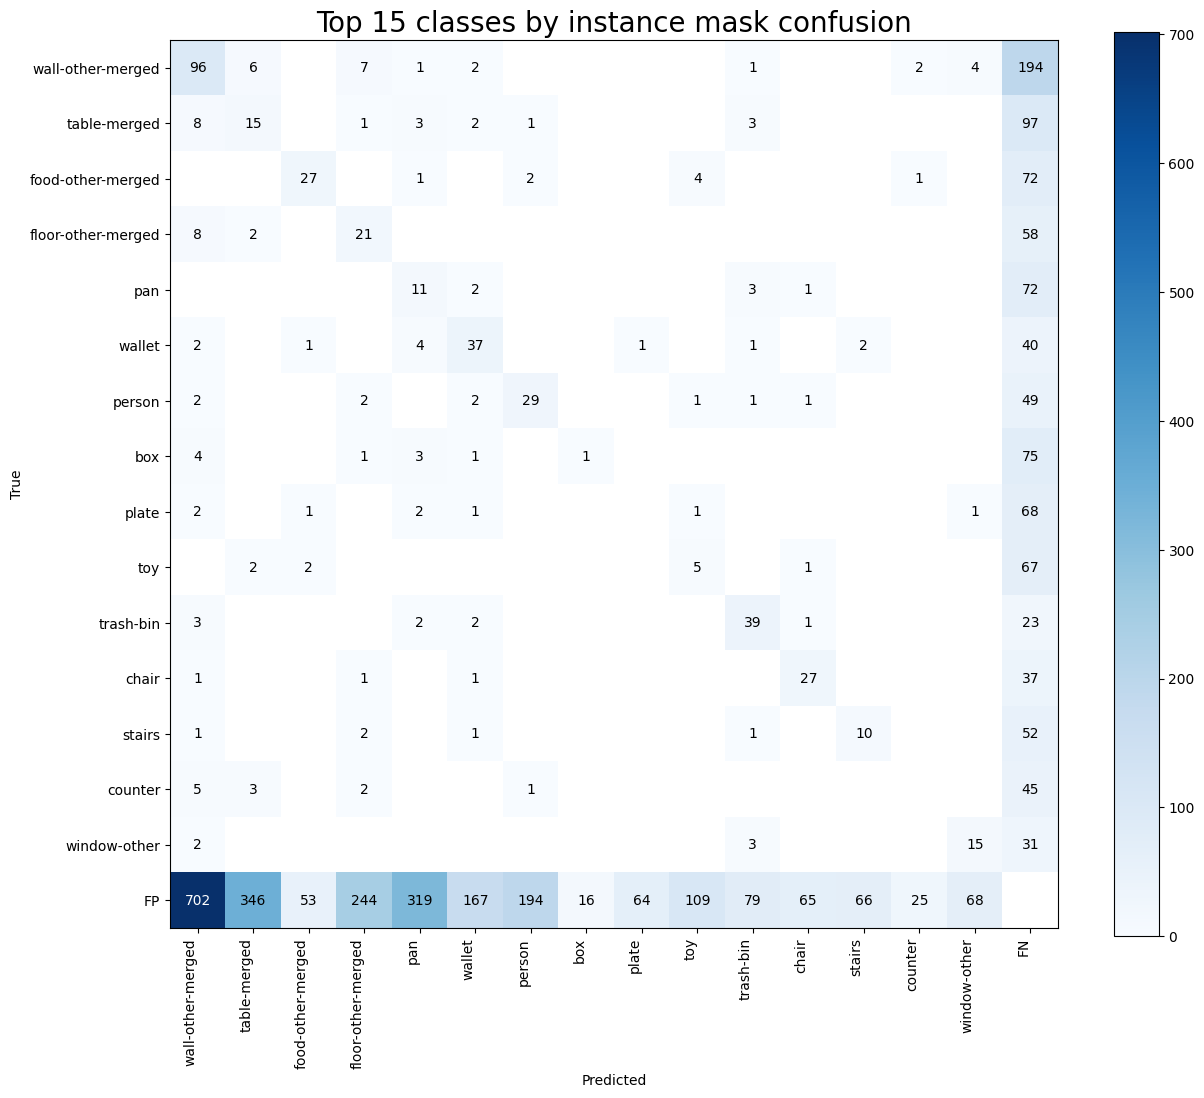

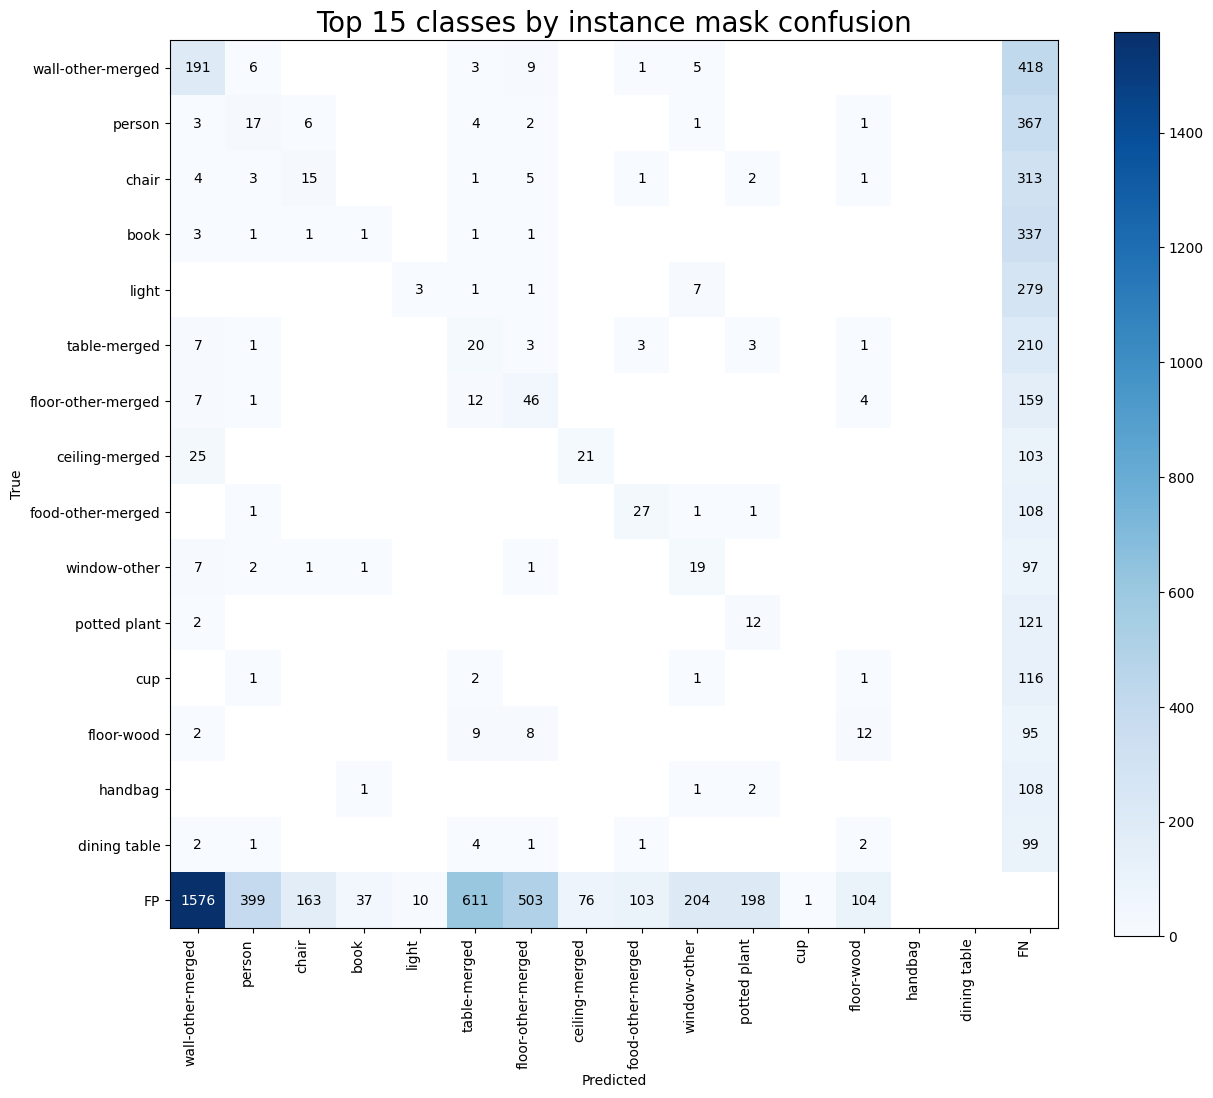

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import supervision as sv
from supervision.metrics import MetricTarget
from PIL import Image, ImageDraw
from train_maskrcnn import COCOSegmentationDataset, build_model, collate_fn
from torch.utils.data import DataLoader


CLASS_NAMES = [item["name"] for item in sorted(train_annotations["categories"], key=lambda item: item["id"])]
BACKGROUND_INDEX = len(CLASS_NAMES)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


def render_mask_overlay(image, masks, labels, class_names, scores=None):
    overlay = image.copy()
    colors = plt.get_cmap("tab20")
    for index, mask in enumerate(masks):
        class_index = int(labels[index])
        color = (np.asarray(colors(class_index % 20)[:3]) * 255).astype(np.uint8)
        mask = np.asarray(mask, dtype=bool)
        overlay[mask] = (0.45 * overlay[mask] + 0.55 * color).astype(np.uint8)
    rendered = Image.fromarray(overlay)
    draw = ImageDraw.Draw(rendered)
    for index, class_index in enumerate(labels):
        label = class_names[int(class_index)]
        if scores is not None:
            label += f" {float(scores[index]):.2f}"
        draw.text((8, 8 + index * 18), label, fill="white", stroke_width=1, stroke_fill="black")
    return rendered


def save_confusion_outputs(matrix, output_dir):
    labels = CLASS_NAMES + ["background"]
    with (output_dir / "confusion_matrix.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["ground_truth / prediction", *labels])
        for label, row in zip(labels, matrix):
            writer.writerow([label, *row.tolist()])

    top_classes = sorted(range(len(CLASS_NAMES)), key=lambda index: matrix[index].sum(), reverse=True)[:15]
    visible_order = top_classes + [BACKGROUND_INDEX]
    display_matrix = sv.ConfusionMatrix(
        matrix=matrix[np.ix_(visible_order, visible_order)].astype(np.int32),
        classes=[CLASS_NAMES[index] for index in top_classes],
        conf_threshold=0.25,
        iou_threshold=0.5,
        metric_target=MetricTarget.MASKS,
    )
    display_matrix.plot(
        save_path=str(output_dir / "confusion_matrix_top15.png"),
        title="Top 15 classes by instance mask confusion",
        fig_size=(13, 11),
    )


def evaluate_maskrcnn_checkpoint(weights, checkpoint_path, split_dir, split_name):
    output_dir = ARTIFACT_DIR / "maskrcnn" / weights / split_name
    output_dir.mkdir(parents=True, exist_ok=True)
    annotation_file = split_dir / "_annotations.coco.json"
    coco_ground_truth = COCO(str(annotation_file))
    dataset = COCOSegmentationDataset(split_dir, annotation_file, CLASS_NAMES)
    loader = DataLoader(
        dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2,
        collate_fn=collate_fn,
        pin_memory=torch.cuda.is_available(),
    )

    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    model = build_model(len(CLASS_NAMES) + 1, pretrained=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(DEVICE).eval()
    model.roi_heads.score_thresh = 0.001

    category_id_by_name = {
        category["name"]: category["id"]
        for category in coco_ground_truth.dataset["categories"]
    }
    coco_predictions = []
    confusion = np.zeros((len(CLASS_NAMES) + 1, len(CLASS_NAMES) + 1), dtype=np.int64)
    failure_rows = []
    sample_count = 12
    input_dir = output_dir / "sample_inputs"
    ground_truth_dir = output_dir / "sample_ground_truth"
    prediction_dir = output_dir / "sample_predictions"
    for directory in (input_dir, ground_truth_dir, prediction_dir):
        directory.mkdir(parents=True, exist_ok=True)

    with torch.inference_mode():
        for sample_index, (images, targets) in enumerate(loader):
            image_tensor = images[0].to(DEVICE)
            target = targets[0]
            prediction = model([image_tensor])[0]
            image_id = int(target["image_id"].item())
            image_info = coco_ground_truth.loadImgs(image_id)[0]
            image_path = split_dir / image_info["file_name"]
            original_image = (image_tensor.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

            ground_truth_masks = target["masks"].numpy().astype(bool)
            ground_truth_labels = (target["labels"].numpy() - 1).astype(int)
            prediction_masks = prediction["masks"][:, 0].cpu().numpy() > 0.5
            prediction_labels = (prediction["labels"].cpu().numpy() - 1).astype(int)
            scores = prediction["scores"].cpu().numpy()

            ground_truth_detections = (
                sv.Detections(
                    xyxy=target["boxes"].numpy(),
                    mask=ground_truth_masks,
                    class_id=ground_truth_labels,
                )
                if len(ground_truth_labels)
                else sv.Detections.empty()
            )
            prediction_detections = (
                sv.Detections(
                    xyxy=prediction["boxes"].cpu().numpy(),
                    mask=prediction_masks,
                    class_id=prediction_labels,
                    confidence=scores,
                )
                if len(prediction_labels)
                else sv.Detections.empty()
            )
            image_confusion = sv.ConfusionMatrix.from_detections(
                predictions=[prediction_detections],
                targets=[ground_truth_detections],
                classes=CLASS_NAMES,
                conf_threshold=0.25,
                iou_threshold=0.5,
                metric_target=MetricTarget.MASKS,
            ).matrix
            confusion += image_confusion
            matched_classes = image_confusion[:-1, :-1]
            false_positives = int(image_confusion[-1, :-1].sum())
            false_negatives = int(image_confusion[:-1, -1].sum())
            class_mismatches = int(matched_classes.sum() - np.trace(matched_classes))
            failure_rows.append({
                "image": image_info["file_name"],
                "false_positives": false_positives,
                "false_negatives": false_negatives,
                "class_mismatches": class_mismatches,
                "total_errors": false_positives + false_negatives + class_mismatches,
            })

            for prediction_index, score in enumerate(scores):
                class_index = prediction_labels[prediction_index]
                mask = prediction_masks[prediction_index]
                encoded_mask = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
                encoded_mask["counts"] = encoded_mask["counts"].decode("utf-8")
                x1, y1, x2, y2 = prediction["boxes"][prediction_index].cpu().tolist()
                coco_predictions.append({
                    "image_id": image_id,
                    "category_id": category_id_by_name[CLASS_NAMES[class_index]],
                    "score": float(score),
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "segmentation": encoded_mask,
                })

            if sample_index < sample_count:
                Image.fromarray(original_image).save(input_dir / image_path.name)
                ground_truth_overlay = render_mask_overlay(
                    original_image,
                    ground_truth_masks,
                    ground_truth_labels,
                    CLASS_NAMES,
                )
                prediction_overlay = render_mask_overlay(
                    original_image,
                    prediction_masks,
                    prediction_labels,
                    CLASS_NAMES,
                    scores,
                )
                ground_truth_overlay.save(ground_truth_dir / image_path.name)
                prediction_overlay.save(prediction_dir / image_path.name)

    (output_dir / "predictions_coco.json").write_text(json.dumps(coco_predictions), encoding="utf-8")
    save_confusion_outputs(confusion, output_dir)
    failure_rows.sort(key=lambda row: row["total_errors"], reverse=True)
    with (output_dir / "failure_candidates.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file,
            fieldnames=["image", "false_positives", "false_negatives", "class_mismatches", "total_errors"],
        )
        writer.writeheader()
        writer.writerows(failure_rows)

    failure_dir = output_dir / "failure_examples"
    failure_inputs = failure_dir / "inputs"
    failure_ground_truth = failure_dir / "ground_truth"
    failure_predictions = failure_dir / "predictions"
    for directory in (failure_inputs, failure_ground_truth, failure_predictions):
        directory.mkdir(parents=True, exist_ok=True)
    image_info_by_name = {item["file_name"]: item for item in coco_ground_truth.dataset["images"]}
    with torch.inference_mode():
        for failure in failure_rows[:5]:
            image_info = image_info_by_name[failure["image"]]
            image_path = split_dir / image_info["file_name"]
            image_id = int(image_info["id"])
            dataset_index = dataset.image_ids.index(image_id)
            image_tensor, target = dataset[dataset_index]
            image = (image_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
            prediction = model([image_tensor.to(DEVICE)])[0]
            ground_truth_masks = target["masks"].numpy().astype(bool)
            ground_truth_labels = (target["labels"].numpy() - 1).tolist()
            scores = prediction["scores"].cpu().numpy()
            keep = scores >= 0.25
            prediction_masks = prediction["masks"][:, 0].cpu().numpy() > 0.5
            prediction_masks = prediction_masks[keep]
            prediction_labels = (prediction["labels"].cpu().numpy() - 1)[keep].tolist()
            prediction_scores = scores[keep]
            shutil.copy2(image_path, failure_inputs / image_path.name)
            render_mask_overlay(
                image,
                ground_truth_masks,
                ground_truth_labels,
                CLASS_NAMES,
            ).save(failure_ground_truth / image_path.name)
            render_mask_overlay(
                image,
                prediction_masks,
                prediction_labels,
                CLASS_NAMES,
                prediction_scores,
            ).save(failure_predictions / image_path.name)

    metrics = {
        "checkpoint": str(checkpoint_path),
        "split": split_name,
        "images": len(dataset),
        "confusion_score_threshold": 0.25,
        "confusion_mask_iou_threshold": 0.5,
    }
    per_class_ap = []
    if coco_predictions:
        coco_detections = coco_ground_truth.loadRes(coco_predictions)
        for iou_type, prefix in (("segm", "mask"), ("bbox", "box")):
            evaluator = COCOeval(coco_ground_truth, coco_detections, iouType=iou_type)
            evaluator.params.catIds = sorted(coco_ground_truth.getCatIds())
            evaluator.evaluate()
            evaluator.accumulate()
            evaluator.summarize()
            metrics[prefix] = {
                "map_50_95": float(evaluator.stats[0]),
                "map_50": float(evaluator.stats[1]),
                "map_75": float(evaluator.stats[2]),
                "mar_100": float(evaluator.stats[8]),
            }
            if iou_type == "segm":
                precision = evaluator.eval["precision"]
                for category_index, category_id in enumerate(evaluator.params.catIds):
                    values = precision[:, :, category_index, 0, -1]
                    valid_values = values[values > -1]
                    name = next(
                        category["name"]
                        for category in coco_ground_truth.dataset["categories"]
                        if category["id"] == category_id
                    )
                    per_class_ap.append({
                        "class_name": name,
                        "mask_ap_50_95": float(valid_values.mean()) if valid_values.size else None,
                    })
    else:
        metrics["mask"] = {"map_50_95": 0.0, "map_50": 0.0, "map_75": 0.0, "mar_100": 0.0}
        metrics["box"] = {"map_50_95": 0.0, "map_50": 0.0, "map_75": 0.0, "mar_100": 0.0}

    (output_dir / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    with (output_dir / "per_class_mask_ap.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=["class_name", "mask_ap_50_95"])
        writer.writeheader()
        writer.writerows(per_class_ap)
    return metrics


maskrcnn_checkpoints = {
    "pretrained": CHECKPOINT_DIR / "maskrcnn" / "pretrained" / "best.ckpt",
    "scratch": CHECKPOINT_DIR / "maskrcnn" / "scratch" / "best.ckpt",
}
maskrcnn_eval_rows = []
for weights, checkpoint_path in maskrcnn_checkpoints.items():
    maskrcnn_eval_rows.append({"weights": weights, **evaluate_maskrcnn_checkpoint(weights, checkpoint_path, valid, "valid")})
    maskrcnn_eval_rows.append({"weights": weights, **evaluate_maskrcnn_checkpoint(weights, checkpoint_path, test, "original_test")})


with (ARTIFACT_DIR / "maskrcnn_metrics_summary.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=["weights", "split", "images", "mask", "box", "checkpoint"],
        extrasaction="ignore",
    )
    writer.writeheader()
    for row in maskrcnn_eval_rows:
        row["mask"] = json.dumps(row.get("mask", {}))
        row["box"] = json.dumps(row.get("box", {}))
        writer.writerow(row)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
curve_count = 0
for weights in maskrcnn_checkpoints:
    log_file = CHECKPOINT_DIR / "maskrcnn" / weights / "training_log.csv"
    if not log_file.exists():
        continue
    with log_file.open(newline="", encoding="utf-8") as file:
        log_rows = list(csv.DictReader(file))
    epochs = [int(row["epoch"]) for row in log_rows]
    losses = [float(row["train_loss"]) for row in log_rows]
    seconds = [float(row["epoch_seconds"]) / 60 for row in log_rows]
    axes[0].plot(epochs, losses, label=weights)
    axes[1].plot(epochs, seconds, label=weights)
    curve_count += 1
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Epoch duration")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Minutes")
for axis in axes:
    axis.legend()
    axis.grid(True, alpha=0.25)
if curve_count:
    figure.tight_layout()
    figure.savefig(ARTIFACT_DIR / "maskrcnn_training_curves.png", dpi=180)
plt.close(figure)
